# The figures of "Earth-sized tests of long-range neutrino interactions"

This notebook draws every figure of the paper, from the data files in `../data`. Each figure comes with a short explanation: what it shows, how to read it, and which data file holds its numbers. Running the whole notebook rewrites the figures in `../figures` (as PDF files, named after their number in the paper).

**What the paper does.** A new gauge boson $Z'$, very light, could mediate a force between neutrinos and the electrons and nucleons of ordinary matter. Atmospheric neutrinos that cross the Earth would then feel a potential, sourced by the Earth itself, that changes how they oscillate. The paper computes that potential at every point along the path of each neutrino, uses it to analyze 8 years of public IceCube DeepCore data, with a livetime of 2724 days (7.5 years), and sets upper limits on the coupling $g'$ of the $Z'$ for 14 $U(1)'$ symmetries and mediator masses $m'$ from $10^{-15}$ to $10^{-9}$ eV.

**Requirements.** The packages of `../requirements.txt`, and a LaTeX installation on the path: the text of the figures is typeset by LaTeX, in Palatino, as in the paper.

In [1]:
import os
import sys

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import numpy as np
from matplotlib.lines import Line2D
from matplotlib.patches import Circle, ConnectionPatch, PathPatch, Patch, Polygon, Rectangle, Wedge
from matplotlib.ticker import FixedFormatter, FixedLocator, MultipleLocator, NullFormatter, NullLocator

sys.path.insert(0, '..')
from plotting import data, style

style.use()                                    # the paper's style: LaTeX, Palatino, inward ticks
FIGURES = os.path.join('..', 'figures')
os.makedirs(FIGURES, exist_ok=True)
FS = 10                                        # font size of the figures [pt]

## Reading the limits

All the limits of the paper are in `../data/limits.json`, one entry per symmetry. For each, `upper_limit[CL][data]` holds the upper limit on the coupling at the 25 mediator masses of `mediator_mass_eV` (on $g'$; for $L_\mu - L_\tau$, on the effective coupling $G'$ of its mixing with the $Z$, as the field `coupling` says): `CL` is `'90'` or `'95'` (the confidence level, in %), and `data` is `'observed'` (from the DeepCore data) or `'expected'` (from the Asimov data set, the expected events of the fit without a long-range interaction). A `null` means no upper limit at that mass; `upper_limit` itself is `null` for the six symmetries whose potential acts on $\nu_e$ alone, which have none. The file explains every field in its `how_to_read` section.

The cell below prints the observed 90% C.L. limits of every symmetry at four masses.

In [2]:
limits = data.load('limits')
m = data.masses()
pick = [0, 8, 16, 24]                                 # 1e-15, 1e-13, 1e-11, 1e-9 eV
print(f"{'symmetry':26s}" + ''.join(f'{m[i]:12.0e}' for i in pick) + '   (eV)')
for name in data.symmetries():
    g = data.upper_limit(name, cl='90', data='observed')
    print(f'{name:26s}' + ''.join(f'{g[i]:12.2e}' if np.isfinite(g[i]) else f"{'none':>12s}" for i in pick))

symmetry                         1e-15       1e-13       1e-11       1e-09   (eV)
B - 3L_mu                     1.42e-26    3.33e-26    2.60e-24    2.60e-22
L - 3L_mu                     2.04e-26    4.81e-26    3.77e-24    3.77e-22
B - 3L_tau                    1.42e-26    3.33e-26    2.60e-24    2.60e-22
L - 3L_tau                    2.05e-26    4.82e-26    3.78e-24    3.78e-22
L_mu - L_tau (k > 0)          2.86e-26    6.64e-26    5.18e-24    5.18e-22
L_mu - L_tau (k < 0)          2.84e-26    6.64e-26    5.16e-24    5.16e-22
B - L_e - 2L_tau              2.42e-26    5.63e-26    4.39e-24    4.39e-22
L_e - L_mu                    3.54e-26    8.36e-26    6.56e-24    6.56e-22
L_e - L_tau                   3.55e-26    8.36e-26    6.58e-24    6.58e-22
B - 3L_e                          none        none        none        none
L - 3L_e                          none        none        none        none
B - 3/2(L_mu + L_tau)             none        none        none        none
L_e - 1/2(L_mu + L

## Fig. 1. Limits on the coupling of an $L_e - L_\mu$ interaction versus the mediator mass

**What it shows.** The 90% C.L. upper limit on $g'$ for the symmetry $L_e - L_\mu$, whose potential is sourced by the electrons of the Earth (blue, "This work"), against the mediator mass $m'$ (bottom axis) or, equivalently, the interaction range $1/m'$ (top axis). The region above the curve is excluded. The dashed gray curve is the earlier limit from the same DeepCore data (arXiv:2601.01220), which holds the potential of the Earth at its value at the detector along every path; it ends where it leaves the axes of that paper's figure. The hatched region is excluded by tests of the equivalence principle (Eöt-Wash, MICROSCOPE).

**How to read it.** For ranges longer than the Earth's radius (left of the dotted line), the whole Earth sources the potential and the limit barely changes with mass. For shorter ranges, only matter near each neutrino contributes; above about $10^{-12}$ eV the limit grows in proportion to $m'$.

**Data:** `limits.json` (`L_e - L_mu`), `previous_limits.json` (`garg_2026_le_lmu`), `equivalence_principle_bounds.json` (`90`).

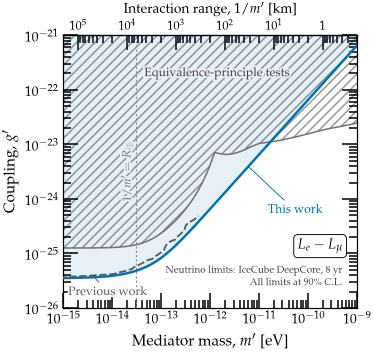

In [3]:
M_MIN, M_MAX = 1e-15, 1e-9
G_MIN, G_MAX = 1e-26, 1e-21
THIS, PREVIOUS = style.COLORS['numu'], '0.35'
M = np.logspace(np.log10(M_MIN), np.log10(M_MAX), 400)
g_this = data.limit_curve(M, 'L_e - L_mu')                   # observed, 90% C.L.
m_prev, g_prev = data.previous_le_lmu()
m_earth = data.HBARC_EV_KM / data.R_EARTH                    # 1/m' = R_Earth

fig, ax = plt.subplots(figsize=(3.4, 3.0))
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(M_MIN, M_MAX)
ax.set_ylim(G_MIN, G_MAX)
ax.set_xlabel(r"Mediator mass, $m'$ [eV]", fontsize=FS)
ax.set_ylabel(r"Coupling, $g'$", fontsize=FS)
ax.tick_params(labelsize=FS - 1)
ax.tick_params(axis='x', which='major', pad=2)
ax.tick_params(top=False, which='both')
top = ax.secondary_xaxis('top', functions=(data.range_km, data.range_km))
top.set_xlabel(r"Interaction range, $1/m'$ [km]", fontsize=FS - 1, labelpad=4)
top.tick_params(labelsize=FS - 2, direction='in', which='both', pad=1.5)
top.xaxis.set_major_formatter(style.km_formatter())

# Tests of the equivalence principle, 90% C.L.: hatched, the region they exclude
SHADE = style.shade_of(THIS, 0.10)                           # the fill of our excluded region
m_ep, g_ep_all = data.ep_bounds('90')
g_ep = g_ep_all['L_e - L_mu']
ax.fill_between(m_ep, g_ep, G_MAX, facecolor='none', edgecolor='0.6', hatch='////', lw=0, zorder=0)
ax.plot(m_ep, g_ep, color='0.45', lw=1.0, zorder=2)
ax.text(4.5e-14, 2.0e-22, 'Equivalence-principle tests', color='0.25', fontsize=FS - 2, ha='left', va='center',
        path_effects=[pe.withStroke(linewidth=2.5, foreground=SHADE)])
# The limits
ax.fill_between(M, g_this, G_MAX, color=THIS, alpha=0.10, lw=0, zorder=1)
ax.plot(M, g_this, color=THIS, lw=1.6, zorder=3)
ax.plot(m_prev, g_prev, color=PREVIOUS, lw=1.2, ls=(0, (4, 1.5)), zorder=3)
# 1/m' = R_Earth
ax.axvline(m_earth, color='0.55', lw=0.7, ls=(0, (2, 2)))
ax.text(m_earth / 1.12, np.sqrt(G_MIN * G_MAX), r"$1/m' = R_\oplus$", color='0.45', fontsize=FS - 2,
        ha='right', va='center', rotation=90, path_effects=[pe.withStroke(linewidth=2.5, foreground=SHADE)])
# Curve labels, with leaders
leader = dict(arrowstyle='-', lw=0.6, shrinkA=1, shrinkB=0)
m0, m1 = 4e-15, 6e-12
ax.annotate('Previous work', xy=(m0, np.exp(np.interp(np.log(m0), np.log(m_prev), np.log(g_prev)))),
            xytext=(1.25e-15, 1.5e-26), color=PREVIOUS, fontsize=FS - 2, ha='left', va='bottom',
            arrowprops=dict(color=PREVIOUS, **leader), path_effects=[pe.withStroke(linewidth=2.5, foreground='w')])
ax.annotate('This work', xy=(m1, data.limit_curve(np.array([m1]), 'L_e - L_mu')[0]), xytext=(1.5e-11, 8e-25),
            color=THIS, fontsize=FS - 2, ha='left', va='top', arrowprops=dict(color=THIS, **leader))
# Model, data and confidence level
ax.text(0.95, 0.20, r'$L_e - L_\mu$', transform=ax.transAxes, fontsize=FS - 1, ha='right', va='bottom',
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='k', lw=0.6))
ax.text(0.95, 0.155, r'Neutrino limits: IceCube DeepCore, 8 yr', transform=ax.transAxes, fontsize=FS - 3.5,
        ha='right', va='top', color='0.25')
ax.text(0.95, 0.11, r'All limits at 90\% C.L.', transform=ax.transAxes, fontsize=FS - 3.5, ha='right', va='top',
        color='0.25')
fig.savefig(os.path.join(FIGURES, 'fig01_limits_Le_Lmu.pdf'), bbox_inches='tight', pad_inches=0.02)
plt.show()

## Fig. 2. An atmospheric neutrino crossing the Earth, with a long-range interaction

**What it shows.** A schematic, not to scale. A cosmic ray hits the atmosphere on the left and makes a shower, which produces a neutrino; the neutrino crosses the Earth and reaches IceCube, at the South Pole, on the right. The left half of the Earth shows its surface, behind which the path is hidden (dashed); the right half shows the interior, in the 12 layers of the Earth model of the IceCube analysis, shaded by density. Around three points of the path, the shaded circles have the radius of the interaction range $1/m'$: the potential at each point comes mostly from the matter within a few ranges of it, so it changes as the neutrino moves. The insets show the detector, with the denser DeepCore strings in blue, and stylized events of the two kinds in the sample, a track and a shower, with hits sized by charge and colored by arrival time (from purple to yellow).

**Data:** `earth.json` (the layers and the land outlines). The detector and the events are stylized, drawn by `plotting/data.py`.

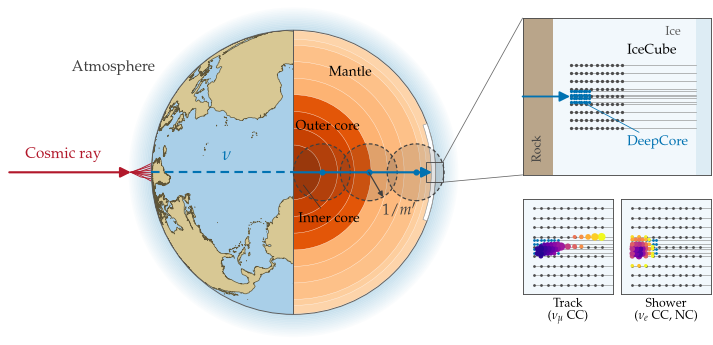

In [4]:
R_KM = data.R_EARTH
ATM = 0.16                                   # drawn thickness of the atmosphere [Earth radii]
OCEAN, LAND, LAND_EDGE, AIR = '#a9cfe8', '#d8c894', '#5f5537', '#9ecae1'
NU, CR, YUKAWA = '#0072B2', '#b2182b', '0.25'

fig = plt.figure(figsize=(7.0, 3.1))
ax = fig.add_axes([0.0, 0.0, 1.0, 1.0])
ax.set_xlim(-2.05, 2.62)
ax.set_ylim(-1.2, 1.2)
ax.set_aspect('equal')
ax.axis('off')

# Atmosphere, fading outward
n_rings = 14
for k in range(n_rings):
    r1 = 1.0 + ATM * (k + 1) / n_rings
    ax.add_patch(Wedge((0, 0), r1, 0, 360, width=ATM / n_rings, color=AIR, alpha=0.6 * (1 - k / n_rings), lw=0))

# Left half: the surface (land seen from above the equator at longitude -40 deg, South Pole at the right)
left = Wedge((0, 0), 1.0, 90, 270, facecolor=OCEAN, edgecolor='none')
ax.add_patch(left)
for ring in data.land_rings():
    patch = Polygon(ring, closed=True, facecolor=LAND, edgecolor=LAND_EDGE, lw=0.45, joinstyle='round')
    ax.add_patch(patch)
    patch.set_clip_path(left)

# Right half: the interior, all 12 layers of the model, shaded by density
cmap, norm = plt.cm.Oranges, matplotlib.colors.Normalize(0.0, 15.0)
for r_in, r_out, rho in reversed(data.earth_layers()):
    ax.add_patch(Wedge((0, 0), r_out / R_KM, -90, 90, facecolor=cmap(norm(rho)), edgecolor='#fff5eb', lw=0.25))
for name, x, y in (('Outer core', 0.24, 0.32), ('Mantle', 0.40, 0.70)):
    ax.text(x, y, name, fontsize=FS - 1, ha='center', va='center')
ax.annotate('Inner core', xy=(0.07, -0.09), xytext=(0.25, -0.33), fontsize=FS - 1, ha='center', va='center',
            arrowprops=dict(arrowstyle='-', color='0.2', lw=0.5, shrinkA=1, shrinkB=0))
ax.add_patch(Wedge((0, 0), 1.0, 90, 270, facecolor='none', edgecolor='0.35', lw=0.6))
ax.add_patch(Wedge((0, 0), 1.0, -90, 90, facecolor='none', edgecolor='0.35', lw=0.6))

# Ice at the South Pole, on the right of the limb
ax.add_patch(Wedge((0, 0), 1.0, -20, 20, width=0.03, facecolor='white', edgecolor='0.6', lw=0.4))

# Cosmic ray, shower and neutrino, along y = 0
x_hit, x_end = -(1.0 + 0.9 * ATM), -1.005
ax.annotate('', xy=(x_hit, 0), xytext=(-2.0, 0),
            arrowprops=dict(arrowstyle='-|>', color=CR, lw=1.4, shrinkA=0, shrinkB=0))
ax.text(-1.62, 0.07, 'Cosmic ray', color=CR, fontsize=FS, ha='center', va='bottom')
rng = np.random.default_rng(3)
for y_end in np.linspace(-0.06, 0.06, 9):
    xm = x_hit + 0.5 * (x_end - x_hit)
    ax.plot([x_hit, xm, x_end], [0, 0.5 * y_end + rng.normal(0, 0.004), y_end], color=CR, lw=0.6)
ax.plot([x_end, -1.0], [0, 0], color=NU, lw=1.4)
ax.plot([-1.0, 0.0], [0, 0], color=NU, lw=1.4, ls=(0, (4, 2.5)))
ax.annotate('', xy=(0.975, 0), xytext=(0.0, 0), arrowprops=dict(arrowstyle='-|>', color=NU, lw=1.4, shrinkA=0, shrinkB=0))
ax.text(-0.47, 0.05, r'$\nu$', color=NU, fontsize=FS + 2, ha='center', va='bottom')
a = np.deg2rad(145)
ax.text((1 + ATM + 0.03) * np.cos(a), (1 + ATM + 0.03) * np.sin(a), 'Atmosphere', fontsize=FS, ha='right',
        va='bottom', color='0.25')

# Spheres of radius 1/m', centered on the neutrino at three points of its path
r_y = 0.20
for x_c in (0.20, 0.53, 0.86):
    ax.add_patch(Circle((x_c, 0), r_y, facecolor=YUKAWA, alpha=0.15, edgecolor='none'))
    ax.add_patch(Circle((x_c, 0), r_y, facecolor='none', edgecolor=YUKAWA, lw=0.8, ls=(0, (3, 2))))
    ax.plot([x_c], [0], 'o', color=NU, ms=3.0)
x_c, b = 0.53, np.deg2rad(-60)
ax.annotate('', xy=(x_c + r_y * np.cos(b), r_y * np.sin(b)), xytext=(x_c, 0),
            arrowprops=dict(arrowstyle='-|>', color=YUKAWA, lw=0.8, shrinkA=0, shrinkB=0, mutation_scale=7))
ax.text(x_c + (r_y + 0.03) * np.cos(b) - 0.02, (r_y + 0.03) * np.sin(b) - 0.012, r"$1/m'$", fontsize=FS,
        color=YUKAWA, ha='left', va='top')

# Zoom on IceCube
ax.add_patch(Rectangle((0.93, -0.07), 0.12, 0.14, facecolor='none', edgecolor='0.3', lw=0.6))
doms = data.detector_doms()
U0, U1, V0, V1 = -3.4, 0.3, -1.25, 1.25         # local vertical (minus the depth) and width [km]


def detector(axd, u_range, v_range, full=True):
    # Ice, rock, strings and optical modules, in the orientation of the Earth (up to the right)
    axd.set_xlim(*u_range)
    axd.set_ylim(*v_range)
    axd.set_xticks([])
    axd.set_yticks([])
    for side in axd.spines.values():
        side.set_linewidth(0.6)
        side.set_color('0.3')
    axd.add_patch(Rectangle((u_range[0], v_range[0]), -2.8 - u_range[0], np.ptp(v_range), facecolor='#b9a58a', lw=0))
    axd.add_patch(Rectangle((-2.8, v_range[0]), 2.8, np.ptp(v_range), facecolor='#f2f8fc', lw=0))
    axd.add_patch(Rectangle((0.0, v_range[0]), 1.0, np.ptp(v_range), facecolor=AIR, alpha=0.35, lw=0))
    for v in np.unique(doms[:, 1]):
        deepest = doms[doms[:, 1] == v, 0].max()
        axd.plot([-deepest, 0.0], [v, v], color='0.55', lw=0.4, zorder=1)
    ic, dc = doms[:, 2] == 0, doms[:, 2] == 1
    axd.plot(-doms[ic, 0], doms[ic, 1], 'o', color='0.3', ms=1.1 if full else 0.8, zorder=2)
    axd.plot(-doms[dc, 0], doms[dc, 1], 'o', color=NU, ms=1.1 if full else 0.8, zorder=2)


# The insets, raised so that the top one sits close to the top of the atmosphere
ax.apply_aspect()
top = fig.transFigure.inverted().transform(ax.transData.transform((0.0, 1.0 + ATM)))[1]
INSET_H = 0.46
SHIFT = 0.7 * (top - (0.42 + INSET_H))
ins = fig.add_axes([0.745, 0.42 + SHIFT, 0.245, INSET_H])
detector(ins, (U0, U1), (V0, V1))
ins.annotate('', xy=(-2.47, 0.0), xytext=(U0, 0.0), arrowprops=dict(arrowstyle='-|>', color=NU, lw=1.2, shrinkA=0, shrinkB=0))
U_LABEL = -1.35
ins.text(U_LABEL, 0.62, 'IceCube', fontsize=FS - 1, ha='left', va='bottom')
ins.annotate('DeepCore', xy=(-2.2, -0.1), xytext=(U_LABEL, -0.62), fontsize=FS - 1, ha='left', va='top', color=NU,
             arrowprops=dict(arrowstyle='-', color=NU, lw=0.5, shrinkA=0, shrinkB=1))
ins.text(-0.45, 1.12, 'Ice', fontsize=FS - 2, ha='center', va='top', color='0.35')
ins.text(-3.1, -1.05, 'Rock', fontsize=FS - 2, ha='center', va='bottom', color='0.25', rotation=90)
for (xa, ya), (xb, yb) in (((1.05, 0.07), (0, 1)), ((1.05, -0.07), (0, 0))):
    fig.add_artist(ConnectionPatch(xyA=(xa, ya), coordsA=ax.transData, xyB=(xb, yb), coordsB=ins.transAxes,
                                   color='0.4', lw=0.5))

# Two example events, stylized: a track and a shower
for k, (kind, title) in enumerate((('track', 'Track\n' + r'($\nu_\mu$ CC)'), ('shower', 'Shower\n' + r'($\nu_e$ CC, NC)'))):
    ev = fig.add_axes([0.745 + k * 0.1275, 0.07 + SHIFT, 0.1175, 0.28])
    detector(ev, (-2.62, -1.28), (-0.62, 0.62), full=False)
    hits = data.event_hits(kind)
    ev.scatter(-hits['depth'], hits['transverse'], s=4 + 26 * hits['charge'], c=hits['time'], cmap='plasma',
               vmin=0, vmax=1, edgecolors='none', zorder=3)
    ev.text(0.5, -0.04, title, transform=ev.transAxes, fontsize=FS - 2, ha='center', va='top', linespacing=1.0)

fig.savefig(os.path.join(FIGURES, 'fig02_setup.pdf'), bbox_inches='tight', pad_inches=0.02)
plt.show()

## Fig. 3. The long-range potential inside the Earth, relative to its value at the detector

**What it shows.** The potential of $L_e - L_\mu$, sourced by the electrons of the Earth, divided by its value at the detector, for three interaction ranges: the Earth's radius $R_\oplus$, $0.1\,R_\oplus$ and $0.01\,R_\oplus$ (columns). *Top:* in a cross-section of the Earth, with two paths to IceCube, one through the center ($\cos\theta_z = -1$, light blue) and one through the mantle ($\cos\theta_z = -0.4$, green). *Bottom:* the potential along each path, against the distance traveled inside the Earth; the shaded steps are the electron density along the path relative to that at the detector (gray for the central path, green for the other).

**How to read it.** A potential held at its value at the detector would be the dashed line at 1. Along the path through the core, the potential grows to several times that value, more so for shorter ranges; along the path through the mantle it grows less. Only for ranges well below 1 km does the potential follow the density itself.

**Data:** `potential.json` (one entry per range: the radial profile, and the two paths).

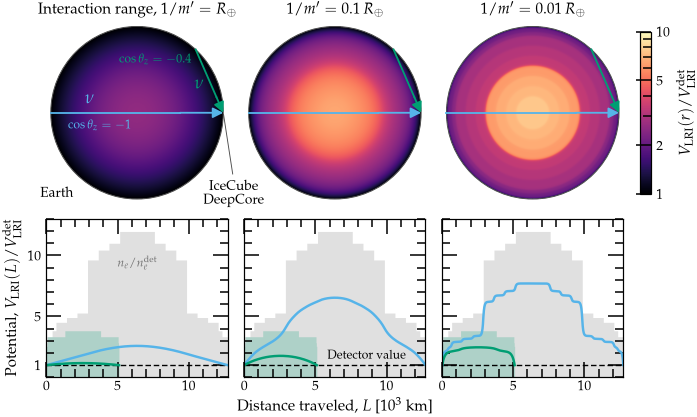

In [5]:
RANGES = ((r"Interaction range, $1/m' = R_\oplus$"), (r"$1/m' = 0.1\,R_\oplus$"), (r"$1/m' = 0.01\,R_\oplus$"))
PATHS = ((-1.0, '#56B4E9', r'$\cos\theta_z = -1$'), (-0.4, '#009E73', r'$\cos\theta_z = -0.4$'))
log_norm = matplotlib.colors.LogNorm(1.0, 10.0)
pot = data.load('potential')

fig = plt.figure(figsize=(7.0, 4.0))
grid = fig.add_gridspec(2, 4, width_ratios=[1, 1, 1, 0.06], height_ratios=[1.0, 0.8], hspace=0.04, wspace=0.12)
profile_axes = []
for col, title in enumerate(RANGES):
    # Top: the cross-section, with the two paths
    axm = fig.add_subplot(grid[0, col])
    im = axm.imshow(data.potential_map(col), extent=(-1, 1, -1, 1), origin='lower', cmap='magma', norm=log_norm)
    axm.add_patch(Circle((0, 0), 1.0, fill=False, color='0.3', lw=0.6))
    for cz, color, label in PATHS:
        start, det = data.path_chord(cz)
        mid = start + 0.75 * (det - start)
        axm.plot([start[0], mid[0]], [start[1], mid[1]], color=color, lw=1.2)
        axm.annotate('', xy=det, xytext=mid, arrowprops=dict(arrowstyle='-|>', color=color, lw=1.2, shrinkA=0, shrinkB=0))
    if col == 0:
        axm.text(-0.55, 0.05, r'$\nu$', color=PATHS[0][1], fontsize=FS + 2, ha='center', va='bottom')
        axm.text(-0.80, -0.08, PATHS[0][2], color=PATHS[0][1], fontsize=FS - 2, ha='left', va='top')
        start, det = data.path_chord(PATHS[1][0])
        axm.text(start[0] - 0.05, start[1] - 0.05, PATHS[1][2], color=PATHS[1][1], fontsize=FS - 2, ha='right', va='top')
        mid = 0.5 * (start + det)
        axm.text(mid[0] - 0.12, mid[1] - 0.04, r'$\nu$', color=PATHS[1][1], fontsize=FS + 2, ha='center', va='center')
        Y_LABEL = -0.94
        axm.text(-0.93, Y_LABEL, 'Earth', fontsize=FS - 1, ha='center', va='center')
        axm.annotate('IceCube\nDeepCore', xy=det, xytext=(1.12, Y_LABEL), fontsize=FS - 1, ha='center', va='center',
                     linespacing=1.0, arrowprops=dict(arrowstyle='-', color='0.3', lw=0.6, shrinkA=2, shrinkB=1,
                                                      relpos=(0.5, 1.0)))
    axm.set_xlim(-1.05, 1.05)
    axm.set_ylim(-1.05, 1.05)
    axm.set_aspect('equal')
    axm.axis('off')
    axm.text(0, 1.1, title, fontsize=FS, ha='center', va='bottom')

    # Bottom: along each path, with its own density ratio shaded
    axp = fig.add_subplot(grid[1, col])
    for k, (cz, color, label) in enumerate(PATHS):
        d = pot['ranges'][col]['paths'][k]
        L = np.array(d['distance_km']) / 1e3
        if k == 0:
            axp.fill_between(L, 0, d['density_ratio'], color='0.88', lw=0, step='mid', zorder=0)
        else:
            axp.fill_between(L, 0, d['density_ratio'], color=color, alpha=0.22, lw=0, step='mid', zorder=0.5)
        axp.plot(L, d['ratio'], color=color, lw=1.6, zorder=2)
    axp.axhline(1.0, color='k', lw=0.9, ls=(0, (4, 2)), zorder=1)
    axp.set_xlim(0, data.path_length(-1.0) / 1e3)
    axp.set_ylim(0, 13.0)
    axp.xaxis.set_major_locator(MultipleLocator(5))
    axp.xaxis.set_minor_locator(MultipleLocator(1))
    axp.yaxis.set_major_locator(FixedLocator([1, 5, 10]))
    axp.yaxis.set_minor_locator(MultipleLocator(1))
    axp.tick_params(axis='x', which='major', labelsize=FS - 1, pad=2)
    axp.tick_params(axis='y', labelsize=FS - 1)
    if col == 0:
        axp.set_ylabel(r'Potential, $V_{\rm LRI}(L)/V_{\rm LRI}^{\rm det}$', fontsize=FS)
        axp.text(6.37, 9.4, r'$n_e/n_e^{\rm det}$', fontsize=FS - 2, ha='center', va='center', color='0.45')
    else:
        axp.set_yticklabels([])
    if col == 1:
        axp.text(8.6, 1.25, 'Detector value', fontsize=FS - 2, ha='center', va='bottom')
    profile_axes.append(axp)
profile_axes[1].set_xlabel(r'Distance traveled, $L$ [$10^3$ km]', fontsize=FS, labelpad=2)

cax = fig.add_subplot(grid[0, 3])
cb = fig.colorbar(im, cax=cax, ticks=[1, 2, 5, 10])
cb.ax.set_yticklabels(['1', '2', '5', '10'])
cb.set_label(r'$V_{\rm LRI}(r)/V_{\rm LRI}^{\rm det}$', fontsize=FS)
cb.ax.tick_params(labelsize=FS - 1)
pos = cax.get_position()
cax.set_position([pos.x0, pos.y0 + 0.09 * pos.height, pos.width, 0.82 * pos.height])

fig.savefig(os.path.join(FIGURES, 'fig03_potential.pdf'), bbox_inches='tight', pad_inches=0.02)
plt.show()

## Fig. 4. Muon-neutrino survival probability versus energy and direction

**What it shows.** The probability that a muon neutrino is still a muon neutrino when it reaches the detector, against its energy and its direction, $\cos\theta_z$ ($-1$: from directly below, through the center of the Earth; $0$: from the horizon). *Top:* standard oscillations. *Bottom:* the change caused by the benchmark interaction, $L_e - L_\mu$ with $1/m' = 0.1\,R_\oplus$ and $g' = 2.34 \times 10^{-25}$, close to the expected limit at that range. Neutrinos are produced 20 km above the surface, with the best-fit oscillation parameters of the DeepCore analysis.

**How to read it.** The dotted line marks the core-mantle boundary: directions below it cross the core. The colored lines mark the two paths of Figs. 3 and 5. The largest changes lie below 10 GeV, in directions that cross the core, where the probability oscillates fastest with energy.

**Data:** `oscillograms.json`.

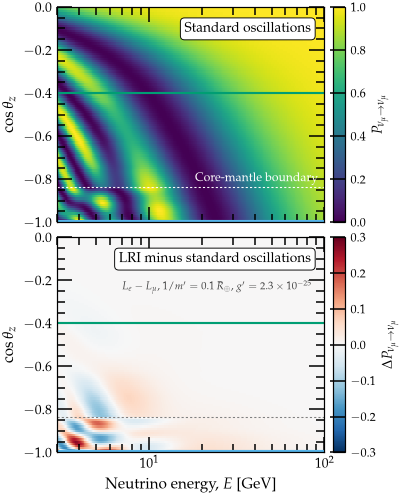

In [6]:
E_MIN, E_MAX = 3.0, 100.0
PMM = r'$P_{\nu_\mu \to \nu_\mu}$'
BENCHMARK_LABEL = r"$L_e - L_\mu$, $1/m' = 0.1\,R_\oplus$, $g' = 2.3 \times 10^{-25}$"
BOX = dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='k', lw=0.6)
osc = data.load('oscillograms')
E2, CZ = np.array(osc['energy_GeV']), np.array(osc['cos_zenith'])
P_std, P_lri = np.array(osc['survival_standard']), np.array(osc['survival_lri'])
cz_cmb = osc['cos_zenith_core_mantle_boundary']

fig, axes = plt.subplots(2, 1, figsize=(3.4, 4.9), sharex=True, gridspec_kw={'hspace': 0.07})
panels = ((P_std, 'viridis', (0, 1), 'Standard oscillations', PMM),
          (P_lri - P_std, 'RdBu_r', (-0.3, 0.3), 'LRI minus standard oscillations', r'$\Delta$' + PMM))
for k, (ax, (z, cmap, (lo, hi), label, clabel)) in enumerate(zip(axes, panels)):
    mesh = ax.pcolormesh(E2, CZ, z, cmap=cmap, vmin=lo, vmax=hi, shading='auto', rasterized=True)
    ax.set_xscale('log')
    ax.set_xlim(E_MIN, E_MAX)
    ax.set_ylim(-1.0, 0.0)
    ax.axhline(cz_cmb, color='w' if k == 0 else '0.5', lw=0.7, ls=(0, (2, 2)))
    for cz, color, _ in PATHS:                       # the two paths of Figs. 3 and 5 (cos = -1 raised to show)
        ax.axhline(cz + (0.006 if cz == -1.0 else 0.0), color=color, lw=1.4)
    ax.text(0.95, 0.93, label, transform=ax.transAxes, fontsize=FS - 1, ha='right', va='top', bbox=BOX)
    ax.set_ylabel(r'$\cos\theta_z$', fontsize=FS)
    ax.yaxis.set_minor_locator(MultipleLocator(0.05))
    ax.tick_params(labelsize=FS - 1)
    cb = fig.colorbar(mesh, ax=ax, pad=0.03, fraction=0.06, aspect=18)
    cb.set_label(clabel, fontsize=FS - 1)
    cb.ax.tick_params(labelsize=FS - 2)
    if k == 0:
        ax.text(0.92 * E_MAX, cz_cmb + 0.012, 'Core-mantle boundary', color='w', fontsize=FS - 2, ha='right', va='bottom')
    else:
        ax.text(0.95, 0.80, BENCHMARK_LABEL, transform=ax.transAxes, fontsize=FS - 3, ha='right', va='top', color='0.25')
axes[1].set_xlabel(r'Neutrino energy, $E$ [GeV]', fontsize=FS)
axes[1].tick_params(axis='x', which='major', pad=2)
fig.savefig(os.path.join(FIGURES, 'fig04_oscillograms.pdf'), bbox_inches='tight', pad_inches=0.02)
plt.show()

## Fig. 5. Muon-neutrino survival probability versus energy, along two paths

**What it shows.** The survival probability of Fig. 4 along the two paths of Fig. 3: through the center of the Earth (top) and through the mantle (bottom), without the interaction (dashed gray) and with it (solid). The inset magnifies the maximum near 5 GeV along $\cos\theta_z = -0.4$.

**How to read it.** Along the path through the center, the interaction shifts the maxima below 10 GeV and lifts the minimum near 24 GeV above zero; that filled minimum, seen in steeply up-going tracks, is what makes DeepCore sensitive to the interaction. Along the path through the mantle, where the potential is weaker, the probability changes only slightly.

**Data:** `probabilities.json`.

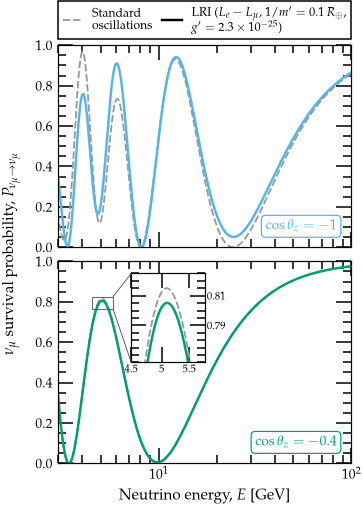

In [7]:
STD_LS = (0, (4, 1.5))                                   # standard oscillations: dashed
prob = data.load('probabilities')
E1 = np.array(prob['energy_GeV'])

fig, axes = plt.subplots(2, 1, figsize=(3.4, 4.6), sharex=True, gridspec_kw={'hspace': 0.07})
curves = []
for ax, (cz, color, label), path in zip(axes, PATHS, prob['paths']):
    curves.append((np.array(path['survival_standard']), np.array(path['survival_lri'])))
    ax.plot(E1, curves[-1][0], color='0.6', lw=1.2, ls=STD_LS)
    ax.plot(E1, curves[-1][1], color=color, lw=1.6)
    ax.set_xscale('log')
    ax.set_xlim(E_MIN, E_MAX)
    ax.set_ylim(0, 1)
    ax.yaxis.set_major_locator(FixedLocator([0, 0.2, 0.4, 0.6, 0.8, 1.0]))
    ax.yaxis.set_minor_locator(MultipleLocator(0.05))
    ax.tick_params(labelsize=FS - 1)
    ax.text(0.95, 0.07, label, transform=ax.transAxes, fontsize=FS - 1, color=color, ha='right', va='bottom',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor=color, lw=0.8))

handles = [Line2D([], [], color='0.6', lw=1.2, ls=STD_LS), Line2D([], [], color='k', lw=1.6)]
axes[0].legend(handles, ['Standard\noscillations',
                         'LRI (' + r"$L_e - L_\mu$, $1/m' = 0.1\,R_\oplus$," + '\n' + r"$g' = 2.3 \times 10^{-25}$)"],
               loc='lower left', bbox_to_anchor=(0.0, 1.03, 1.0, 0.2), mode='expand', ncol=2, borderaxespad=0.0,
               fontsize=FS - 2, frameon=True, fancybox=False, edgecolor='k', framealpha=1, handlelength=1.6,
               columnspacing=0.8)

# Zoom on the maximum at 5.1 GeV along cos(theta_z) = -0.4, where the two curves nearly overlap
E_ZOOM, P_ZOOM = (4.5, 5.8), (0.765, 0.825)
axins = axes[1].inset_axes([0.25, 0.50, 0.25, 0.44])
for p_curve, kw in zip(curves[1], (dict(color='0.6', lw=1.2, ls=STD_LS), dict(color=PATHS[1][1], lw=1.6))):
    axins.plot(E1, p_curve, **kw)
axins.set_xscale('log')
axins.set_xlim(*E_ZOOM)
axins.set_ylim(*P_ZOOM)
axins.xaxis.set_major_locator(FixedLocator([4.5, 5.0, 5.5]))
axins.xaxis.set_major_formatter(FixedFormatter(['4.5', '5', '5.5']))
axins.xaxis.set_minor_locator(NullLocator())
axins.yaxis.set_major_locator(FixedLocator([0.79, 0.81]))
axins.yaxis.set_minor_locator(MultipleLocator(0.005))
axins.tick_params(labelsize=FS - 3, pad=1.5)
axins.tick_params(axis='y', labelleft=False, labelright=True)
axes[1].indicate_inset_zoom(axins, edgecolor='0.35', lw=0.6, alpha=1)
for p_box, y_inset in ((P_ZOOM[1], 1.0), (P_ZOOM[0], 0.0)):
    fig.add_artist(ConnectionPatch(xyA=(E_ZOOM[1], p_box), coordsA=axes[1].transData, xyB=(0.0, y_inset),
                                   coordsB=axins.transAxes, color='0.35', lw=0.6))

axes[0].set_ylabel(r'$\nu_\mu$ survival probability, ' + PMM, fontsize=FS)
axes[0].yaxis.set_label_coords(-0.13, -0.035)
axes[1].set_xlabel(r'Neutrino energy, $E$ [GeV]', fontsize=FS)
axes[1].tick_params(axis='x', which='major', pad=2)
fig.savefig(os.path.join(FIGURES, 'fig05_probabilities.pdf'), bbox_inches='tight', pad_inches=0.02)
plt.show()

## Fig. 6. Observed events of the IceCube DeepCore sample, and their pulls against the fit without a long-range interaction

**What it shows.** *Left:* the observed events in the 200 analysis bins: 10 bins of reconstructed energy, 10 of reconstructed direction $\cos\theta_{\rm reco}$, and two particle-identification channels ("Mixed", top; "Tracks", bottom). *Right:* in each bin, the pull $(N_{\rm obs} - N_{\rm fit})/\sigma$ of the observed events against their expectation at our best fit without a long-range interaction, where $\sigma^2$ is $N_{\rm fit}$ plus the variance from the finite simulated sample.

**How to read it.** The fit describes the data well, with $\chi^2 = 180.3$ for 200 bins and 20 free parameters.

**Data:** `events.json` (`observed`, `best_fit`, `mc_variance`).

chi2 at the best fit: 180.34


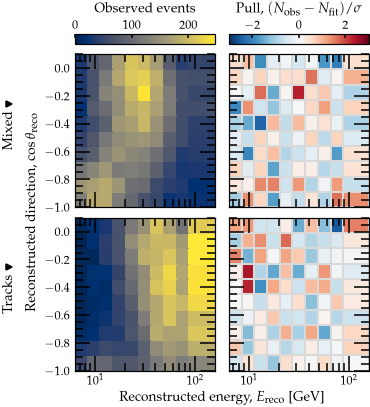

In [8]:
ev = data.load('events')
E_EDGES, CZ_EDGES = np.array(ev['reco_energy_edges_GeV']), np.array(ev['reco_cos_zenith_edges'])
CHANNELS = (('mixed', 'Mixed'), ('tracks', 'Tracks'))
E_LABEL = r'Reconstructed energy, $E_{\rm reco}$ [GeV]'
CZ_LABEL = r'$\cos\theta_{\rm reco}$'


def reco_axes(ax):
    # The axes of the analysis bins
    ax.set_xscale('log')
    ax.set_xlim(E_EDGES[0], E_EDGES[-1])
    ax.set_ylim(CZ_EDGES[0], CZ_EDGES[-1])
    ax.yaxis.set_major_locator(FixedLocator([-1.0, -0.8, -0.6, -0.4, -0.2, 0.0]))
    ax.yaxis.set_minor_locator(MultipleLocator(0.05))
    ax.tick_params(labelsize=FS - 1)


obs = {ch: np.array(ev['channels'][ch]['observed']) for ch, _ in CHANNELS}
fit_ = {ch: np.array(ev['channels'][ch]['best_fit']) for ch, _ in CHANNELS}
var = {ch: np.array(ev['channels'][ch]['mc_variance']) for ch, _ in CHANNELS}
print(f"chi2 at the best fit: {ev['chi2_best_fit']:.2f}")
pull_bf = {ch: (obs[ch] - fit_[ch]) / np.sqrt(fit_[ch] + var[ch]) for ch, _ in CHANNELS}
n_max = max(obs[ch].max() for ch, _ in CHANNELS)

fig = plt.figure(figsize=(3.4, 3.7))
grid = fig.add_gridspec(3, 2, height_ratios=[0.06, 1, 1], hspace=0.10, wspace=0.10)
bottom_axes, left_axes = [], []
for row, (ch, name) in enumerate(CHANNELS):
    for col, (z, cmap, lo, hi) in enumerate(((obs[ch], 'cividis', 0, n_max), (pull_bf[ch], 'RdBu_r', -3, 3))):
        ax = fig.add_subplot(grid[row + 1, col])
        mesh = ax.pcolormesh(E_EDGES, CZ_EDGES, z.T, cmap=cmap, vmin=lo, vmax=hi,
                             edgecolors='0.85' if col else 'face', linewidth=0.2, rasterized=(col == 0))
        reco_axes(ax)
        ax.tick_params(labelsize=FS - 2)
        if col == 0:
            left_axes.append(ax)
        else:
            ax.set_yticklabels([])
        if row == 0:
            ax.set_xticklabels([])
            cax = fig.add_subplot(grid[0, col])
            cb = fig.colorbar(mesh, cax=cax, orientation='horizontal')
            cax.xaxis.set_ticks_position('top')
            cax.xaxis.set_label_position('top')
            cb.set_label('Observed events' if col == 0 else r'Pull, $(N_{\rm obs} - N_{\rm fit})/\sigma$',
                         fontsize=FS - 1, labelpad=5)
            cb.ax.tick_params(labelsize=FS - 2, length=2.5, pad=1.5)
            cb.ax.tick_params(which='minor', length=1.5)
        else:
            ax.tick_params(axis='x', which='major', pad=2)
            bottom_axes.append(ax)

# One x-axis label under both columns; one y-axis label for both rows, and the channel names
fig.canvas.draw()
left, right = bottom_axes[0].get_position(), bottom_axes[1].get_position()
fig.text(0.5 * (left.x0 + right.x1), left.y0 - 0.05, E_LABEL, fontsize=FS - 1, ha='center', va='top')
renderer = fig.canvas.get_renderer()
to_fig = fig.transFigure.inverted()
x_ticks = min(to_fig.transform(t.get_window_extent(renderer).p0)[0]
              for a in left_axes for t in a.get_yticklabels() if t.get_text())
top_, bottom_ = left_axes[0].get_position(), left_axes[1].get_position()
common = fig.text(x_ticks - 0.015, 0.5 * (bottom_.y0 + top_.y1), r'Reconstructed direction, ' + CZ_LABEL,
                  fontsize=FS - 1, rotation=90, ha='right', va='center')
x_rows = to_fig.transform(common.get_window_extent(renderer).p0)[0]
for a, (ch, name) in zip(left_axes, CHANNELS):
    pos = a.get_position()
    label = fig.text(x_rows - 0.025, 0.5 * (pos.y0 + pos.y1), name, fontsize=FS - 1, rotation=90, ha='right', va='center')
    box = to_fig.transform(label.get_window_extent(renderer))
    fig.add_artist(Line2D([box[:, 0].mean()], [box[1, 1] + 0.018], marker='>', ms=3.7, color='k', ls='none',
                          transform=fig.transFigure))
fig.savefig(os.path.join(FIGURES, 'fig06_data_and_fit.pdf'), bbox_inches='tight', pad_inches=0.02)
plt.show()

## Fig. 7. Change in the expected events caused by a long-range interaction

**What it shows.** For the benchmark interaction of Figs. 4 and 5, the change in the expected events of each bin, $(N_{\rm LRI} - N_{\rm std})/\sigma$, with the best-fit oscillation parameters of the DeepCore analysis and nominal nuisance parameters; $\sigma$ is that of Fig. 6. The $\Delta\chi^2$ of each panel is the sum of the squares of its bins.

**How to read it.** The change concentrates in steeply up-going tracks near 24 GeV, where the interaction partly fills the oscillation minimum (Fig. 5). Letting the oscillation and nuisance parameters vary, as the analysis does, can only lower these $\Delta\chi^2$.

**Data:** `events.json` (`benchmark_standard`, `benchmark_standard_mc_variance`, `benchmark_lri`).

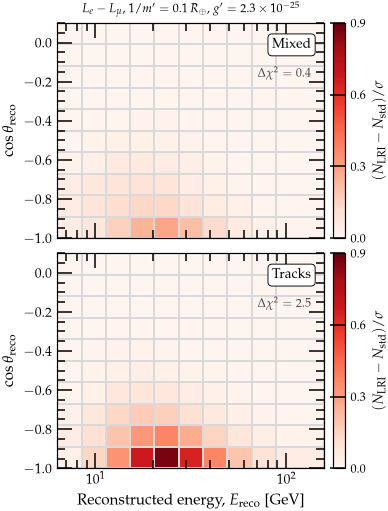

In [9]:
pull_lri = {}
for ch, _ in CHANNELS:
    c = ev['channels'][ch]
    std, lri = np.array(c['benchmark_standard']), np.array(c['benchmark_lri'])
    pull_lri[ch] = (lri - std) / np.sqrt(std + np.array(c['benchmark_standard_mc_variance']))

fig, axes = plt.subplots(2, 1, figsize=(3.4, 4.9), sharex=True, gridspec_kw={'hspace': 0.07})
for ax, (ch, name) in zip(axes, CHANNELS):
    mesh = ax.pcolormesh(E_EDGES, CZ_EDGES, pull_lri[ch].T, cmap='Reds', vmin=0.0, vmax=0.9, edgecolors='0.85',
                         linewidth=0.2)
    reco_axes(ax)
    ax.text(0.95, 0.93, name, transform=ax.transAxes, fontsize=FS - 1, ha='right', va='top', bbox=BOX)
    ax.text(0.95, 0.80, r'$\Delta\chi^2 = ' + f'{np.sum(pull_lri[ch]**2):.1f}' + '$', transform=ax.transAxes,
            fontsize=FS - 2, ha='right', va='top', color='0.25')
    ax.set_ylabel(CZ_LABEL, fontsize=FS)
    cb = fig.colorbar(mesh, ax=ax, pad=0.03, fraction=0.06, aspect=18, ticks=[0, 0.3, 0.6, 0.9])
    cb.set_label(r'$(N_{\rm LRI} - N_{\rm std})/\sigma$', fontsize=FS - 1)
    cb.ax.tick_params(labelsize=FS - 2)
axes[0].text(0.5, 1.03, BENCHMARK_LABEL, transform=axes[0].transAxes, fontsize=FS - 2, ha='center', va='bottom')
axes[1].set_xlabel(E_LABEL, fontsize=FS)
axes[1].tick_params(axis='x', which='major', pad=2)
fig.savefig(os.path.join(FIGURES, 'fig07_lri_in_bins.pdf'), bbox_inches='tight', pad_inches=0.02)
plt.show()

## Fig. 8. Limits on the effective couplings of the symmetries that have an upper limit (and Fig. F.1, at 95% C.L.)

**What it shows.** The 90% C.L. upper limits of the eight symmetries that have one, on the effective coupling $g'\sqrt{|k|}$, where $k$ is the charge factor of each symmetry (the paper's Table I, and `charge_factor_k` in `limits.json`). In these units, the eight curves fall into two groups, colored by the flavors the potential acts on: the six that act on $\nu_\mu$, $\nu_\tau$, $\nu_e - \nu_\mu$ or $\nu_e - \nu_\tau$ (blue), and the two that act on $\nu_\mu - \nu_\tau$ (green), whose limits are about 1.45 times stronger. Each colored band of solid curves is several overlapping curves, one per symmetry; the two insets zoom in on them, at $10^{-11}$ eV (blue) and $10^{-10}$ eV (green), where they are straight lines. ($L_\mu - L_\tau$ with $k > 0$ has the same curve as $B - L_e - 2L_\tau$ in these units, so it is not drawn separately.)

The dashed curves are the earlier limits of arXiv:2606.03443 for the same eight symmetries, read off its Fig. 1 and multiplied by $\sqrt{|k|}$; each ends where it leaves the axes of that figure. Its limit on $L_\mu - L_\tau$ uses a charge of 1 per neutron, not the charge of its own Eq. (7), so it lies 15% below its $B - L_e - 2L_\tau$ curve here. The gray bands are the bounds from tests of the equivalence principle (EP) in the same units: each symmetry has its own, and the bands span them over the four symmetries with $B$ and no $L_e$ (upper band) and over the others (lower band); hatching marks the side they exclude. $L_\mu - L_\tau$ has no such bound.

The six symmetries whose potential acts on $\nu_e$ alone have no upper limit; Fig. F.2 shows the intervals of couplings excluded for two of them.

**Fig. F.1** is the same figure at 95% C.L., with the EP bounds at 95% C.L. and our 90% C.L. limits in a lighter shade, for comparison; it has no earlier limits, which are at 90% C.L.

**Data:** `limits.json`, `previous_limits.json` (`garg_2026_symmetries`), `equivalence_principle_bounds.json`.

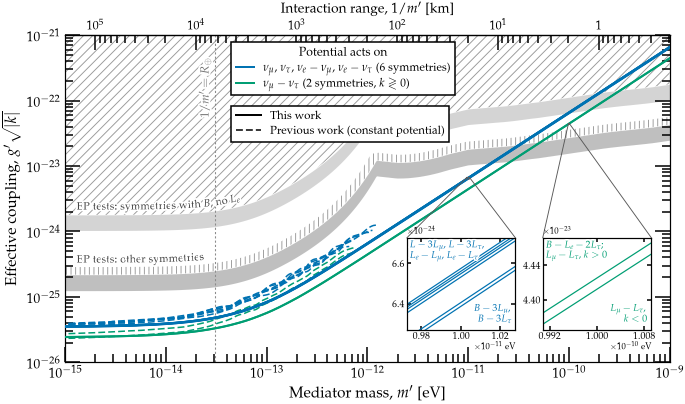

In [10]:
OKABE_ITO = ('#0072B2', '#56B4E9', '#009E73', '#E69F00', '#D55E00', '#CC79A7')
MUTAU, OTHER, NUE = OKABE_ITO[2], OKABE_ITO[0], OKABE_ITO[5]
SIX = ['L_e - L_mu', 'B - 3L_mu', 'L - 3L_mu', 'B - 3L_tau', 'L - 3L_tau', 'L_e - L_tau']
TWO = ['L_mu - L_tau (k < 0)', 'B - L_e - 2L_tau']
GROUP = {**{s: OTHER for s in SIX}, **{s: MUTAU for s in TWO}}
PREVIOUS_GROUP = {'L_e - L_mu': OTHER, 'L_e - L_tau': OTHER, 'L - 3L_mu': OTHER, 'L - 3L_tau': OTHER,
                  'B - 3L_mu': OTHER, 'B - 3L_tau': OTHER, 'L_mu - L_tau': MUTAU, 'B - L_e - 2L_tau': MUTAU}
DASH = (0, (4.5, 2.0))
LIGHT = 0.45                      # opacity over white of the lighter shades


def limits_axes(ax, g_min=G_MIN, g_max=G_MAX, xlabelpad=None, label_shift=1.12):
    # The axes of Figs. 8, F.1 and F.2: mass, interaction range on top, the line of 1/m' = R_Earth
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlim(M_MIN, M_MAX)
    ax.set_ylim(g_min, g_max)
    ax.set_xlabel(r"Mediator mass, $m'$ [eV]", fontsize=FS, labelpad=xlabelpad)
    ax.set_ylabel(r"Effective coupling, $g'\sqrt{|k|}$", fontsize=FS)
    ax.tick_params(labelsize=FS - 1)
    ax.tick_params(axis='x', which='major', pad=2)
    ax.tick_params(top=False, which='both')
    top = ax.secondary_xaxis('top', functions=(data.range_km, data.range_km))
    top.set_xlabel(r"Interaction range, $1/m'$ [km]", fontsize=FS - 1, labelpad=4)
    top.tick_params(labelsize=FS - 2, direction='in', which='both', pad=1.5)
    top.xaxis.set_major_formatter(style.km_formatter())
    ax.axvline(m_earth, color='0.55', lw=0.7, ls=(0, (2, 2)))
    ax.text(m_earth / label_shift, g_max / 2.2, r"$1/m' = R_\oplus$", color='0.45', fontsize=FS - 2, ha='right',
            va='top', rotation=90, path_effects=[pe.withStroke(linewidth=2.5, foreground='w')])


def draw_ep_bands(ax, cl, g_max=G_MAX, label_other=1.3e-15):
    # The EP bounds at confidence level cl, as two bands, hatched on the side they exclude, labeled along them
    m_ep, bands = data.ep_bands(cl)
    for key, alpha in (('B', 0.30), ('other', 0.45)):
        ax.fill_between(m_ep, *bands[key], color='0.45', alpha=alpha, lw=0, zorder=0)
    above = np.vstack([np.column_stack([m_ep, bands['B'][1]]), [[m_ep[-1], g_max], [m_ep[0], g_max]]])
    strip = style.side_strip(ax, m_ep, bands['other'][1], 5.0)
    with matplotlib.rc_context({'hatch.linewidth': 0.6}):
        ax.add_patch(PathPatch(style.closed_path(above), facecolor='none', edgecolor='0.6', hatch='////', lw=0, zorder=0))
        ax.add_patch(PathPatch(style.closed_path(strip), facecolor='none', edgecolor='0.6', hatch='||||', lw=0, zorder=0))
    stroke = [pe.withStroke(linewidth=2.2, foreground='w')]
    style.curved_text(ax, m_ep, bands['B'][1], r'EP tests: symmetries with $B$, no $L_e$', 1.3e-15, offset_pt=1.5,
                      color='0.25', fontsize=FS - 3, path_effects=stroke, zorder=6)
    style.curved_text(ax, m_ep, bands['other'][1], 'EP tests: other symmetries', label_other, offset_pt=6.0,
                      color='0.25', fontsize=FS - 3, path_effects=stroke, zorder=6)


def zoom_inset(ax, rect, members, m_c, half_dex, rel, xticks, yticks, xexp, yexp, labels, fmt, cl='90'):
    # An inset of our curves of `members` around the mass m_c (+-half_dex in log m), from rel[0] to rel[1]
    # times their mean at m_c; ticks in units of 10^xexp eV and 10^yexp
    axi = ax.inset_axes(rect)
    lo, hi = m_c * 10**-half_dex, m_c * 10**half_dex
    Mi = np.logspace(np.log10(lo), np.log10(hi), 100)
    c0 = np.mean([data.limit_curve(np.array([m_c]), s, cl, effective=True)[0] for s in members])
    for s in members:
        axi.plot(Mi, data.limit_curve(Mi, s, cl, effective=True), color=GROUP[s], lw=0.8)
    axi.set_xscale('log')
    axi.set_yscale('log')
    axi.set_xlim(lo, hi)
    axi.set_ylim(c0 * rel[0], c0 * rel[1])
    for a_, ticks, e, f_ in ((axi.xaxis, xticks, xexp, fmt[0]), (axi.yaxis, yticks, yexp, fmt[1])):
        a_.set_minor_locator(NullLocator())
        a_.set_minor_formatter(NullFormatter())
        a_.set_major_locator(FixedLocator(ticks))
        a_.set_major_formatter(FixedFormatter([('$' + f_ + '$') % (t / 10**e) for t in ticks]))
    axi.tick_params(labelsize=FS - 3.5, pad=1.5, length=2.5)
    axi.text(1.0, -0.13, r'$\times 10^{%d}$ eV' % xexp, transform=axi.transAxes, fontsize=FS - 4.25, ha='right', va='top')
    axi.text(0.0, 1.02, r'$\times 10^{%d}$' % yexp, transform=axi.transAxes, fontsize=FS - 4.25, ha='left', va='bottom')
    for t, x, y, ha in labels:
        axi.text(x, y, t, transform=axi.transAxes, fontsize=FS - 3.5, ha=ha, va='center', color=GROUP[members[0]],
                 path_effects=[pe.withStroke(linewidth=2.0, foreground='w')])
    axi.set_facecolor('w')
    ax.indicate_inset_zoom(axi, edgecolor='0.35', lw=0.6, alpha=1)


INSET_TICKS = {'90': ([6.4e-24, 6.6e-24, 6.8e-24], [4.40e-23, 4.44e-23]),
               '95': ([7.0e-24, 7.2e-24], [4.80e-23, 4.90e-23])}


def fig8(cl, out_name):
    M = np.logspace(np.log10(M_MIN), np.log10(M_MAX), 600)
    fig, ax = plt.subplots(figsize=(7.0, 3.6))
    limits_axes(ax, xlabelpad=matplotlib.rcParams['axes.labelpad'] - 1.5, label_shift=1.08)
    draw_ep_bands(ax, cl)
    if cl == '90':                                 # the earlier limits, times our sqrt|k|
        for s, (m, g) in data.previous_symmetries().items():
            k = data.charge_factor('L_mu - L_tau (k > 0)' if s == 'L_mu - L_tau' else s)
            ax.plot(m, g * np.sqrt(abs(k)), color=PREVIOUS_GROUP[s], lw=1.0, ls=DASH, zorder=2.5)
    else:                                          # our 90% C.L. limits, lighter
        for s, color in GROUP.items():
            ax.plot(M, data.limit_curve(M, s, '90', effective=True), color=style.shade_of(color, LIGHT), lw=1.3, zorder=2.8)
    for s, color in GROUP.items():
        ax.plot(M, data.limit_curve(M, s, cl, effective=True), color=color, lw=1.3, zorder=3)
    tb, tg = INSET_TICKS[cl]
    zoom_inset(ax, [0.565, 0.10, 0.18, 0.28], SIX, 1e-11, 0.012, (0.965, 1.035), [0.98e-11, 1.0e-11, 1.02e-11], tb, -11, -24,
               [(r'$L - 3L_\mu$, $L - 3L_\tau$,' '\n' r'$L_e - L_\mu$, $L_e - L_\tau$', 0.03, 0.86, 'left'),
                (r'$B - 3L_\mu$,' '\n' r'$B - 3L_\tau$', 0.96, 0.17, 'right')], ('%.2f', '%.1f'), cl)
    zoom_inset(ax, [0.79, 0.10, 0.18, 0.28], TWO, 1e-10, 0.004, (0.988, 1.012), [0.992e-10, 1.0e-10, 1.008e-10], tg, -10, -23,
               [(r'$B - L_e - 2L_\tau$;' '\n' r'$L_\mu - L_\tau$, $k > 0$', 0.03, 0.86, 'left'),
                (r'$L_\mu - L_\tau$,' '\n' r'$k < 0$', 0.96, 0.17, 'right')], ('%.3f', '%.2f'), cl)
    legend_kw = dict(fontsize=FS - 2.5, frameon=True, fancybox=False, edgecolor='k', framealpha=1, labelspacing=0.3,
                     borderpad=0.4)
    groups = ax.legend([Line2D([], [], color=OTHER, lw=1.3), Line2D([], [], color=MUTAU, lw=1.3)],
                       [r'$\nu_\mu$, $\nu_\tau$, $\nu_e - \nu_\mu$, $\nu_e - \nu_\tau$ (6 symmetries)',
                        r'$\nu_\mu - \nu_\tau$ (2 symmetries, $k \gtrless 0$)'],
                       title='Potential acts on', title_fontsize=FS - 2, loc='upper left', bbox_to_anchor=(0.265, 0.995),
                       handlelength=1.6, **legend_kw)
    ax.add_artist(groups)
    if cl == '90':
        styles = ([Line2D([], [], color='k', lw=1.3), Line2D([], [], color='k', lw=1.0, ls=DASH)],
                  ['This work', 'Previous work (constant potential)'])
    else:
        styles = ([Line2D([], [], color='k', lw=1.3), Line2D([], [], color=style.shade_of('k', LIGHT), lw=1.3)],
                  [r'This work, 95\%~C.L.', r'This work, 90\%~C.L.\ (Fig.~8)'])
    ax.legend(*styles, loc='upper left', bbox_to_anchor=(0.265, 0.80), handlelength=2.2, **legend_kw)
    fig.savefig(os.path.join(FIGURES, out_name), bbox_inches='tight', pad_inches=0.02)
    plt.show()


fig8('90', 'fig08_all_symmetries.pdf')

## Fig. B.1. Atmospheric neutrino flux used in this work

**What it shows.** The flux of atmospheric neutrinos and antineutrinos of the muon and electron flavors that enter the analysis, before oscillations or absorption inside the Earth, averaged over up-going directions ($-1 \leq \cos\theta_z \leq 0$) and over the twelve months, times $E^3$. It is computed with MCEq.

**How to read it.** Muon neutrinos and antineutrinos dominate, increasingly so at higher energies, where more atmospheric muons, the main source of electron neutrinos, reach the ground before decaying.

**Data:** `flux.json`.

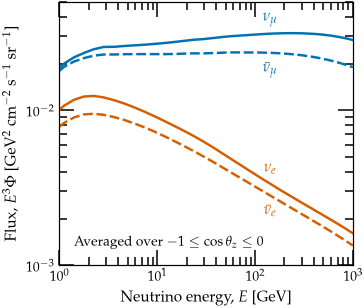

In [11]:
C = style.COLORS
fl = data.load('flux')
E = np.array(fl['energy_GeV'])
phi = {k: np.array(v) for k, v in fl['flux'].items()}
CURVES = (('numu', C['numu'], '-', r'$\nu_\mu$'), ('antinumu', C['numu'], STD_LS, r'$\bar\nu_\mu$'),
          ('nue', C['nue'], '-', r'$\nu_e$'), ('antinue', C['nue'], STD_LS, r'$\bar\nu_e$'))

fig, ax = plt.subplots(figsize=(3.4, 2.9))
for f_, color, ls, label in CURVES:
    ax.plot(E, E**3 * phi[f_], color=color, ls=ls, lw=1.6)
E_LAB = np.sqrt(100.0 * 200.0)                    # each curve named between 100 and 200 GeV
for (f_, color, ls, label), factor, va in zip(CURVES, (1.12, 0.89, 1.12, 0.89), ('bottom', 'top', 'bottom', 'top')):
    ax.text(E_LAB, factor * E_LAB**3 * np.interp(np.log(E_LAB), np.log(E), phi[f_]), label, color=color, fontsize=FS,
            ha='center', va=va)
ax.text(0.05, 0.06, r'Averaged over $-1 \leq \cos\theta_z \leq 0$', transform=ax.transAxes, fontsize=FS - 1,
        ha='left', va='bottom')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(1, 1e3)
ax.set_ylim(1e-3, 5e-2)
ax.yaxis.set_minor_formatter(NullFormatter())
ax.set_xlabel(r'Neutrino energy, $E$ [GeV]', fontsize=FS)
ax.set_ylabel(r'Flux, $E^3 \Phi$ [GeV$^2$ cm$^{-2}$ s$^{-1}$ sr$^{-1}$]', fontsize=FS)
ax.tick_params(labelsize=FS - 1)
ax.tick_params(axis='x', which='major', pad=2)
fig.savefig(os.path.join(FIGURES, 'figB1_flux.pdf'), bbox_inches='tight', pad_inches=0.02)
plt.show()

## Fig. D.1. Nuisance parameters at the fit without a long-range interaction

**What it shows.** The nuisance parameters of the DeepCore analysis at our fit to the data without a long-range interaction (blue circles), next to those of the DeepCore analysis itself (open squares; its Table IV, with the Honda flux). *Top:* the parameters with a Gaussian prior, as pulls $(\theta - \theta_0)/\sigma_\theta$, where $\theta_0$ is the nominal value and $\sigma_\theta$ the width of the prior; the gray band spans one width. Dotted lines separate the parameters of the detector, the flux and the cross sections. *Bottom:* the parameters without a prior, as shifts from their nominal values.

**How to read it.** Both fits keep every parameter with a prior within one width of it.

**Data:** `nuisance_pulls.json`.

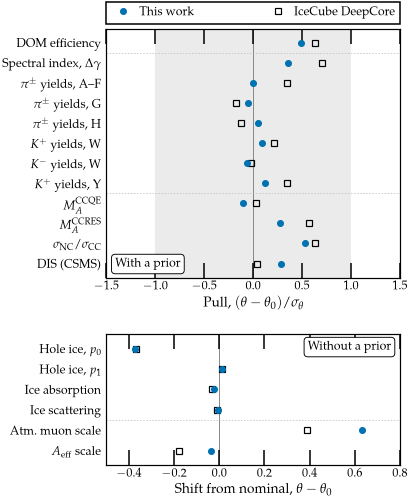

In [12]:
pulls = data.load('nuisance_pulls')
PARAMETER_LABELS = {
    'dom_eff': 'DOM efficiency', 'hole_ice_p0': r'Hole ice, $p_0$', 'hole_ice_p1': r'Hole ice, $p_1$',
    'bulk_ice_abs': 'Ice absorption', 'bulk_ice_scatter': 'Ice scattering', 'delta_gamma': r'Spectral index, $\Delta\gamma$',
    'barr_af_pi': r'$\pi^\pm$ yields, A--F', 'barr_g_pi': r'$\pi^\pm$ yields, G', 'barr_h_pi': r'$\pi^\pm$ yields, H',
    'barr_w_k': r'$K^+$ yields, W', 'barr_w_antik': r'$K^-$ yields, W', 'barr_y_k': r'$K^+$ yields, Y',
    'ma_ccqe': r'$M_A^{\rm CCQE}$', 'ma_ccres': r'$M_A^{\rm CCRES}$', 'nc_norm': r'$\sigma_{\rm NC}/\sigma_{\rm CC}$',
    'dis_csms': 'DIS (CSMS)', 'atm_mu_scale': r'Atm.\ muon scale', 'aeff_scale': r'$A_{\rm eff}$ scale'}
GROUP_ENDS = {'pull': ('dom_eff', 'barr_y_k'), 'shift': ('bulk_ice_scatter',)}
OURS = dict(ls='none', marker='o', ms=3.6, color=style.COLORS['numu'])
DEEPCORE = dict(ls='none', marker='s', ms=4.2, mfc='none', mec='k', mew=0.8)

fig = plt.figure(figsize=(3.4, 4.8))
grid = fig.add_gridspec(2, 1, height_ratios=[len(pulls['pull']) + 0.6, len(pulls['shift']) + 0.6], hspace=0.30)
panels = (('pull', (-1.5, 1.5), r'Pull, $(\theta - \theta_0)/\sigma_\theta$', 'With a prior'),
          ('shift', (-0.5, 0.8), r'Shift from nominal, $\theta - \theta_0$', 'Without a prior'))
for row, (kind, xlim, xlabel, title) in enumerate(panels):
    ax = fig.add_subplot(grid[row])
    names = list(pulls[kind])
    y = np.arange(len(names))[::-1]
    if kind == 'pull':
        ax.axvspan(-1, 1, color='0.92', lw=0, zorder=0)
    ax.axvline(0, color='0.5', lw=0.6, zorder=1)
    ax.plot([pulls[kind][k]['deepcore'] for k in names], y, zorder=3, **DEEPCORE)
    ax.plot([pulls[kind][k]['ours'] for k in names], y, zorder=4, **OURS)
    for k in GROUP_ENDS[kind]:
        ax.axhline(y[names.index(k)] - 0.5, color='0.75', lw=0.5, ls=(0, (2, 2)))
    ax.set_yticks(y)
    ax.set_yticklabels([PARAMETER_LABELS[k] for k in names], fontsize=FS - 2)
    ax.tick_params(axis='y', which='both', left=False, right=False)
    ax.set_ylim(-0.7, len(names) - 0.3)
    ax.set_xlim(*xlim)
    ax.set_xlabel(xlabel, fontsize=FS - 1, labelpad=2)
    ax.tick_params(axis='x', labelsize=FS - 2, pad=2)
    ax.text(0.03 if row == 0 else 0.97, 0.03 if row == 0 else 0.95, title, transform=ax.transAxes, fontsize=FS - 2,
            ha='left' if row == 0 else 'right', va='bottom' if row == 0 else 'top',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='k', lw=0.6))
    if row == 0:
        ax.legend([Line2D([], [], **OURS), Line2D([], [], **DEEPCORE)], ['This work', 'IceCube DeepCore'],
                  loc='lower left', bbox_to_anchor=(0.0, 1.02, 1.0, 0.1), mode='expand', ncol=2, borderaxespad=0.0,
                  fontsize=FS - 2, frameon=True, fancybox=False, edgecolor='k', framealpha=1, handletextpad=0.3,
                  columnspacing=0.8)
fig.savefig(os.path.join(FIGURES, 'figD1_nuisance_parameters.pdf'), bbox_inches='tight', pad_inches=0.02)
plt.show()

## Fig. F.1. Limits on the effective couplings at 95% C.L.

Fig. 8 at 95% C.L. (see the explanation of Fig. 8 above). The same eight symmetries have upper limits, about 10% weaker than at 90% C.L.; the lighter curves are those of Fig. 8, for comparison.

**Data:** `limits.json` (`upper_limit['95']`), `equivalence_principle_bounds.json` (`95`).

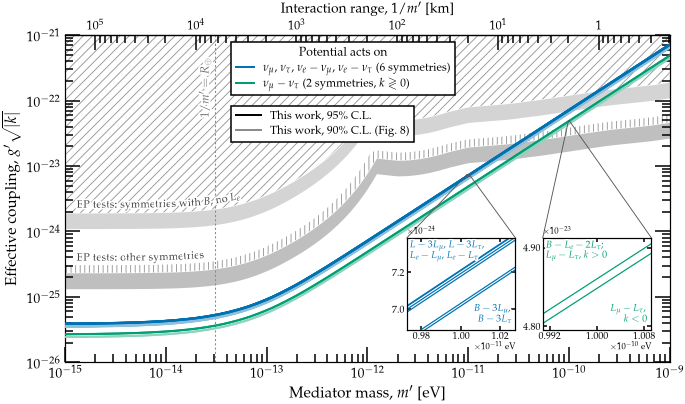

In [13]:
fig8('95', 'figF1_all_symmetries_95CL.pdf')

## Fig. F.2. Bounded intervals of couplings excluded at 90% C.L.

**What it shows.** The two symmetries whose potential acts on $\nu_e$ alone with $k < 0$, $L_e + 2L_\mu + 2L_\tau$ and $B_y + L_\mu + L_\tau$, have no upper limit, but at some masses the data exclude a bounded interval of couplings: at each mass, the couplings between the lower and the upper edge of a band are excluded. The dark bands are those of the data; the light bands, those expected from the Asimov data set. The two symmetries agree within 3% in these units, so their bands overlap. The gray bands are the bounds from tests of the equivalence principle, as in Fig. 8: the bound on $B_y + L_\mu + L_\tau$ lies within the upper band, that on $L_e + 2L_\mu + 2L_\tau$ within the lower one.

**How to read it.** The intervals hold at 90% C.L. only (none at 95% C.L.). On the data they appear at masses up to $10^{-13}$ eV; on the Asimov data set, only from $5.6 \times 10^{-14}$ eV up, so below that mass the data's intervals come from an upward fluctuation. The pseudo-experiments of the paper test the coverage of the upper limits, not that of these intervals.

**Data:** `limits.json` (`excluded_intervals` of the two symmetries), `equivalence_principle_bounds.json` (`90`).

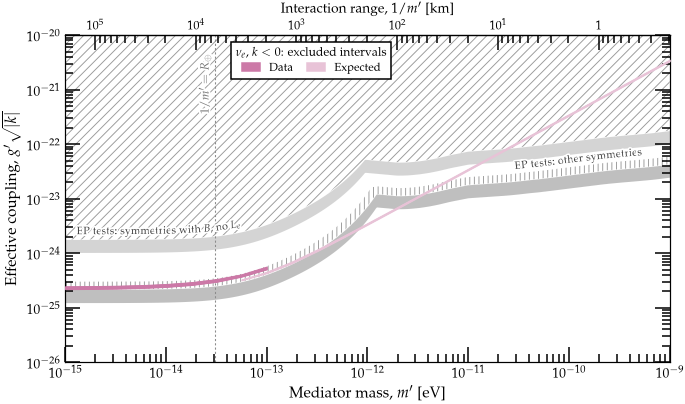

In [14]:
W_MIN, W_MAX = 1e-26, 1e-20                       # the expected intervals reach 3.6e-21 at 1e-9 eV
NUE_LIGHT = style.shade_of(NUE, LIGHT)
fig, ax = plt.subplots(figsize=(7.0, 3.6))
limits_axes(ax, W_MIN, W_MAX, xlabelpad=matplotlib.rcParams['axes.labelpad'] - 1.5, label_shift=1.08)
for which, filled in (('expected', False), ('observed', True)):
    for s in ('L_e + 2L_mu + 2L_tau', 'B_y + L_mu + L_tau'):
        m_w, lo, hi = data.excluded_intervals(s, '90', which, effective=True)
        mm = np.logspace(np.log10(m_w[0]), np.log10(m_w[-1]), 200)
        f = lambda y: 10**np.interp(np.log10(mm), np.log10(m_w), np.log10(y))
        c = NUE if filled else NUE_LIGHT
        ax.fill_between(mm, f(lo), f(hi), color=c, edgecolor=c, lw=0.6, zorder=4 if filled else 3)
draw_ep_bands(ax, '90', W_MAX, label_other=3e-11)      # the lower band's label clear of the data's intervals
legend_kw = dict(fontsize=FS - 2.5, frameon=True, fancybox=False, edgecolor='k', framealpha=1, labelspacing=0.3, borderpad=0.4)
ax.legend([Patch(color=NUE), Patch(color=NUE_LIGHT)], ['Data', 'Expected'], ncol=2, columnspacing=1.2,
          title=r'$\nu_e$, $k < 0$: excluded intervals', title_fontsize=FS - 2, loc='upper left',
          bbox_to_anchor=(0.265, 0.995), handlelength=1.6, **legend_kw)
fig.savefig(os.path.join(FIGURES, 'figF2_excluded_intervals.pdf'), bbox_inches='tight', pad_inches=0.02)
plt.show()